# Clockwise playstyles: exploring the clusters

The same analysis as the dashboard's **Playstyles** tab, in Python, so you can see the charts and check how strong the
clusters really are before trusting the names.

**To use your own games:** in the dashboard, open **Data & settings → Export → JSON** (with the filters you want), save
the file, and point `DATA_PATH` below at it. The defaults run on the repo's sample data, which is synthetic, so expect
weak clusters there.

Sections:
1. How each player's games end (the fates)
2. The features, and what shrinkage does to them
3. How many groups? (silhouette, elbow, Calinski–Harabasz, Davies–Bouldin, GMM BIC)
4. Is there any structure at all? (permutation test against "no real groups")
5. Are the groups stable? (bootstrap over games)
6. The groups: profiles, names, per-player silhouettes
7. The map (PCA biplot) and a dendrogram
8. Hound dogs / framers

In [1]:
# Settings: change these and re-run everything.
DATA_PATH = "../sample-data/botc-sample-games.json"   # your JSON export
SIDE = "good"          # "good", "evil" or "all"
MIN_GAMES = None       # None = the dashboard's default (5 as good, 3 as evil, 5 for all)
K = None               # None = pick by silhouette, or force a number of groups
N_PERMUTATIONS = 200   # for the "is there structure" test
N_BOOTSTRAPS = 200     # for the stability check
SEED = 7

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from sklearn.mixture import GaussianMixture
from scipy.cluster.hierarchy import linkage, dendrogram

from playstyles import (load_games, seat_table, player_table, feature_matrix, name_groups, features_for,
                        FATES, FATE_LABELS, FATE_COLORS, GROUP_COLORS, FEATURES, MIN_GAMES as DEFAULT_MIN)

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
rng = np.random.default_rng(SEED)
min_games = DEFAULT_MIN[SIDE] if MIN_GAMES is None else MIN_GAMES
side_word = {"good": "as good", "evil": "as evil", "all": "in all games"}[SIDE]

games = load_games(DATA_PATH)
seats = seat_table(games)
ended = pd.to_datetime(pd.Series([g.get("endedAt") for g in games]), unit="ms")
print(f"{len(games)} games, {ended.min():%Y-%m-%d} to {ended.max():%Y-%m-%d}")
print(f"{seats['key'].nunique()} players, {len(seats)} seats (travellers left out)")
print(f"{seats['fate'].isna().sum()} seats with unknown fate (died before recording started)")
print(f"{(~seats.drop_duplicates('game')['tracked']).sum()} games joined part-way (left out of nomination stats)")

48 games, 2026-06-03 to 2026-10-18
30 players, 417 seats (travellers left out)
0 seats with unknown fate (died before recording started)
0 games joined part-way (left out of nomination stats)


## 1. How each player's games end

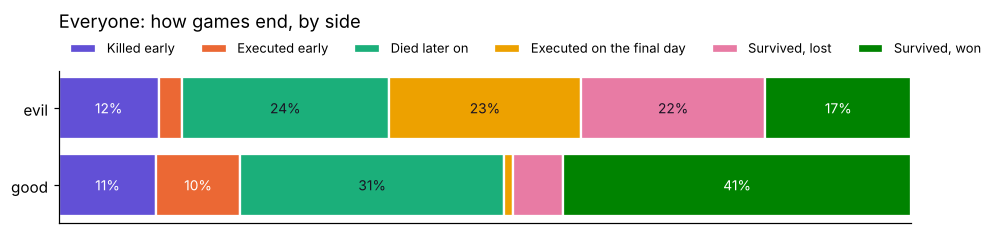

In [3]:
def fate_shares(df):
    known = df[df["fate"].notna()]
    return known["fate"].value_counts(normalize=True).reindex(FATES).fillna(0)

overall = pd.DataFrame({s: fate_shares(seats[seats["side"] == s]) for s in ["good", "evil"]}).T
fig, ax = plt.subplots(figsize=(10, 1.8))
left = np.zeros(len(overall))
for f in FATES:
    ax.barh(overall.index, overall[f], left=left, color=FATE_COLORS[f], label=FATE_LABELS[f], edgecolor="white", linewidth=1.5)
    for i, v in enumerate(overall[f]):
        if v >= 0.07:
            ax.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if f in ("killedEarly", "execEarly", "survivedWon") else "#1a1324")
    left += overall[f].values
ax.set_xlim(0, 1); ax.grid(False); ax.set_xticks([])
ax.legend(ncol=6, bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", frameon=False, fontsize=8.5)
ax.set_title("Everyone: how games end, by side", loc="left", pad=28)
plt.show()

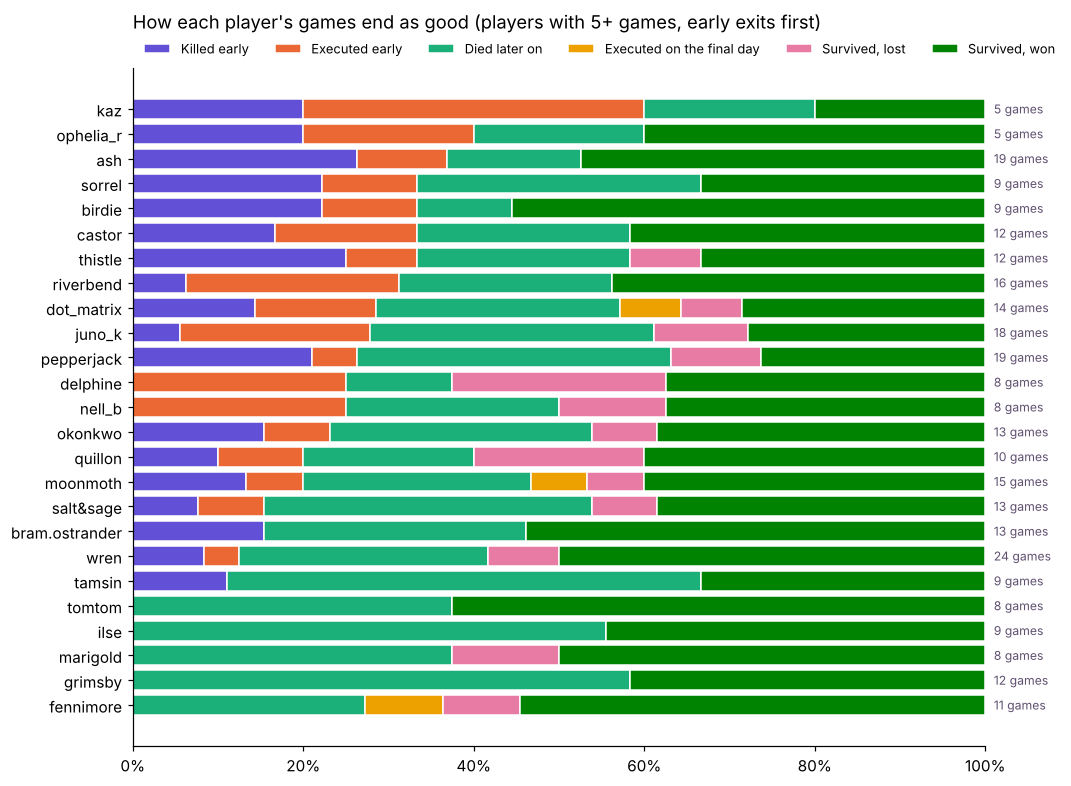

In [4]:
side_seats = seats if SIDE == "all" else seats[seats["side"] == SIDE]
counts = side_seats.groupby("name")["game"].count()
keep = counts[counts >= min_games].index
shares = (side_seats[side_seats["name"].isin(keep) & side_seats["fate"].notna()]
          .groupby("name")["fate"].value_counts(normalize=True).unstack().reindex(columns=FATES).fillna(0))
shares["early"] = shares["killedEarly"] + shares["execEarly"]
shares = shares.sort_values("early")  # early exits at the top of the chart

fig, ax = plt.subplots(figsize=(10, 0.28 * len(shares) + 1))
left = np.zeros(len(shares))
for f in FATES:
    ax.barh(shares.index, shares[f], left=left, color=FATE_COLORS[f], label=FATE_LABELS[f], edgecolor="white", linewidth=1)
    left += shares[f].values
for i, n in enumerate(shares.index):
    ax.text(1.01, i, f"{counts[n]} games", va="center", fontsize=8, color="#5f5070")
ax.set_xlim(0, 1); ax.grid(False); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(ncol=6, bbox_to_anchor=(0, 1.0, 1, 0.2), loc="lower left", frameon=False, fontsize=8.5)
ax.set_title(f"How each player's games end {side_word} (players with {min_games}+ games, early exits first)", loc="left", pad=26)
plt.show()

## 2. The features, and what shrinkage does

Each rate is shrunk toward the table-wide rate: `(count + 5 × table rate) / (games + 5)`. The scatter shows raw vs.
shrunk for one feature: players with few games get pulled hard toward the dashed line (the table rate), players with
many barely move. Change `FEATURE_TO_SHOW` to look at another.

In [5]:
players = player_table(seats, SIDE)
X, feats = feature_matrix(players, SIDE, min_games)
P = players.set_index("name").loc[X.index]
print(f"{len(X)} players with {min_games}+ games {side_word}; features: {', '.join(feats)}")
display(P[["games"] + [f"raw_{f}" for f in feats]].round(2).rename(columns=lambda c: c.replace("raw_", "")).head(30))

25 players with 5+ games as good; features: killedEarly, execEarly, execFinal, survived, winRate, noms, nomAccuracy, enemyExecs, voteAccuracy


,games,killedEarly,execEarly,execFinal,survived,winRate,noms,nomAccuracy,enemyExecs,voteAccuracy
wren,24,0.08,0.04,0.00,0.58,0.71,0.79,0.58,0.21,0.40
pepperjack,19,0.21,0.05,0.00,0.37,0.58,0.42,0.38,0.05,0.22
ash,19,0.26,0.11,0.00,0.47,0.74,0.37,0.29,0.05,0.35
juno_k,18,0.06,0.22,0.00,0.39,0.50,0.39,0.29,0.06,0.30
riverbend,16,0.06,0.25,0.00,0.44,0.50,1.12,0.44,0.19,0.36
moonmoth,15,0.13,0.07,0.07,0.47,0.60,0.53,0.38,0.07,0.43
dot_matrix,14,0.14,0.14,0.07,0.36,0.64,0.57,0.50,0.00,0.38
salt&sage,13,0.08,0.08,0.00,0.46,0.54,0.54,0.29,0.15,0.36
okonkwo,13,0.15,0.08,0.00,0.46,0.62,0.85,0.45,0.08,0.38
bram.ostrander,13,0.15,0.00,0.00,0.54,0.54,0.69,0.44,0.08,0.16


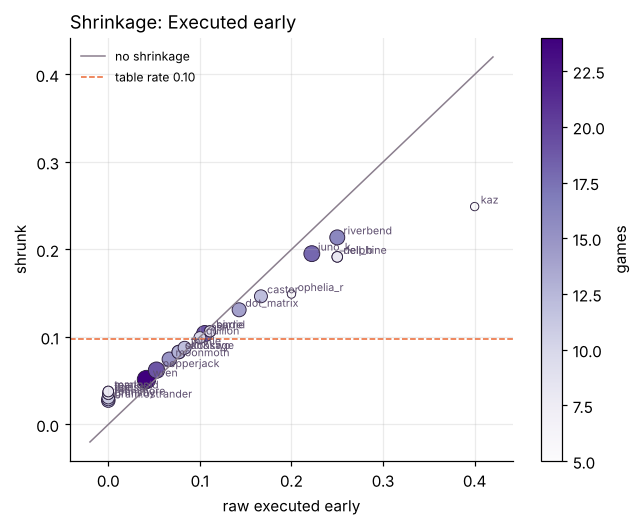

In [6]:
FEATURE_TO_SHOW = "execEarly"
f = FEATURE_TO_SHOW
table_rate = players[FEATURES[f]["num"]].sum() / players[FEATURES[f]["den"]].sum()
fig, ax = plt.subplots(figsize=(6.5, 5))
sc = ax.scatter(P[f"raw_{f}"], P[f"s_{f}"], s=P["games"] * 6, c=P["games"], cmap="Purples", edgecolor="#2b1d3f", linewidth=0.6)
lims = [min(P[f"raw_{f}"].min(), P[f"s_{f}"].min()) - 0.02, max(P[f"raw_{f}"].max(), P[f"s_{f}"].max()) + 0.02]
ax.plot(lims, lims, color="#8b7f8e", lw=1, label="no shrinkage")
ax.axhline(table_rate, color="#eb6834", ls="--", lw=1, label=f"table rate {table_rate:.2f}")
for n, r in P.iterrows():
    ax.annotate(n, (r[f"raw_{f}"], r[f"s_{f}"]), fontsize=7, xytext=(4, 2), textcoords="offset points", color="#5f5070")
ax.set_xlabel(f"raw {FEATURES[f]['label'].lower()}"); ax.set_ylabel("shrunk")
ax.legend(frameon=False, fontsize=8); plt.colorbar(sc, label="games"); ax.set_title(f"Shrinkage: {FEATURES[f]['label']}", loc="left")
plt.show()

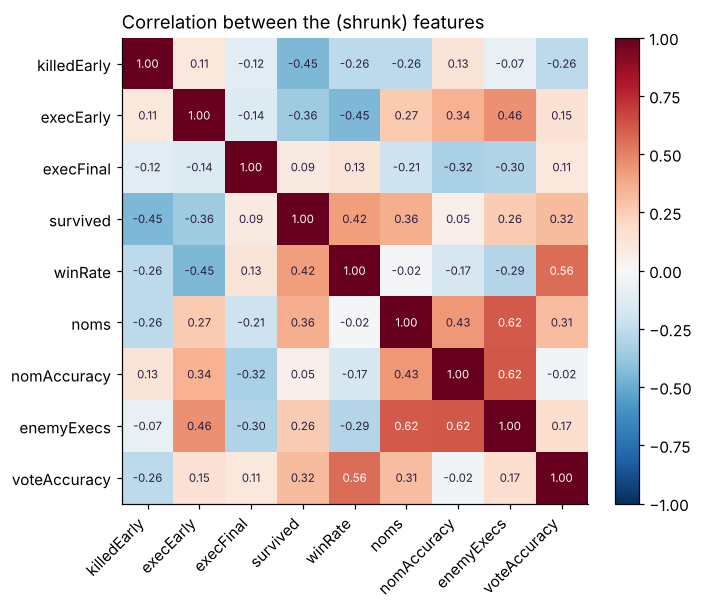

In [7]:
# Features that move together carry the same information twice and pull the clusters toward that axis.
corr = X.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(feats)), feats, rotation=45, ha="right"); ax.set_yticks(range(len(feats)), feats); ax.grid(False)
for i in range(len(feats)):
    for j in range(len(feats)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(corr.iloc[i, j]) > 0.5 else "#2b1d3f")
plt.colorbar(im, fraction=0.046); ax.set_title("Correlation between the (shrunk) features", loc="left")
plt.show()

## 3. How many groups?

Four standard checks for k = 2…8. **Silhouette** (higher is better; above ~0.5 is strong, 0.25–0.5 reasonable, below
0.25 weak) is what the dashboard uses, limited to 2–4 groups. Set `K` at the top to try another number. **Calinski–Harabasz** higher is better, **Davies–Bouldin** lower is better, and the
elbow in **inertia** is where adding a group stops helping much. GMM BIC (lower is better) is a model-based second opinion.

,inertia,silhouette,calinski_harabasz,davies_bouldin,gmm_bic,smallest_group
k,,,,,,
2,177.363,0.154,6.177,1.854,604.472,12
3,142.912,0.164,6.318,1.563,635.528,5
4,125.792,0.178,5.521,1.365,511.298,3
5,110.175,0.162,5.211,1.352,496.232,2
6,96.870,0.170,5.026,1.238,474.500,2
7,81.853,0.181,5.247,1.117,391.168,1
8,70.481,0.202,5.324,0.944,340.740,1


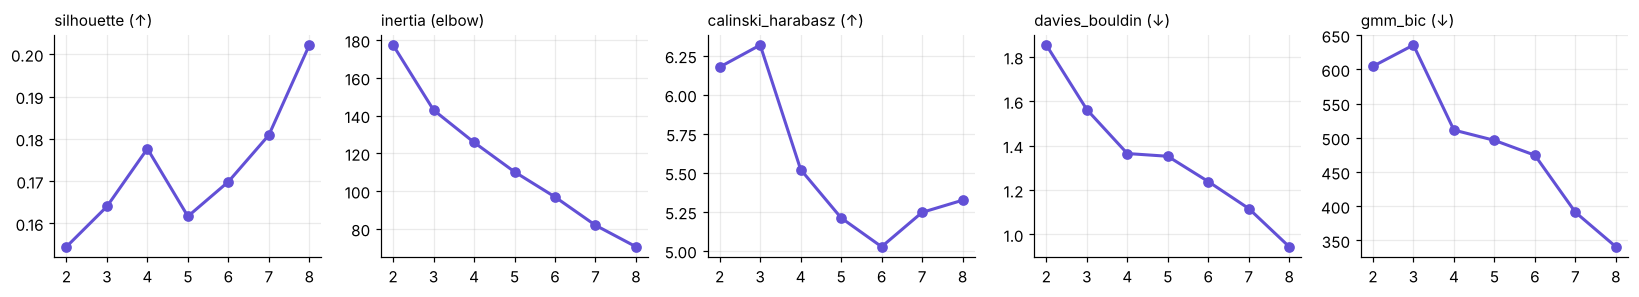

Using k = 4 (the dashboard's rule)


In [8]:
ks = list(range(2, min(8, len(X) // 3) + 1))
rows = []
for k in ks:
    km = KMeans(k, n_init=30, random_state=SEED).fit(X)
    gmm = GaussianMixture(k, covariance_type="diag", n_init=5, random_state=SEED).fit(X.values)
    rows.append(dict(k=k, inertia=km.inertia_, silhouette=silhouette_score(X, km.labels_),
                     calinski_harabasz=calinski_harabasz_score(X, km.labels_), davies_bouldin=davies_bouldin_score(X, km.labels_),
                     gmm_bic=gmm.bic(X.values), smallest_group=np.bincount(km.labels_).min()))
k_scores = pd.DataFrame(rows).set_index("k")
display(k_scores.round(3))

fig, axes = plt.subplots(1, 5, figsize=(15, 2.8))
for ax, col, better in zip(axes, ["silhouette", "inertia", "calinski_harabasz", "davies_bouldin", "gmm_bic"], ["↑", "elbow", "↑", "↓", "↓"]):
    ax.plot(k_scores.index, k_scores[col], marker="o", color="#6250d6", lw=2)
    ax.set_title(f"{col} ({better})", loc="left", fontsize=10); ax.set_xticks(ks)
plt.tight_layout(); plt.show()

# The dashboard's rule: 2–4 groups, no group of one, and a bigger k only if its silhouette is better by more than 0.02
# (silhouette tends to creep up as k grows on small data, splitting off tiny groups).
best_k = K
if best_k is None:
    for k in [k for k in ks if k <= 4 and k_scores.loc[k, "smallest_group"] >= 2]:
        if best_k is None or k_scores.loc[k, "silhouette"] > k_scores.loc[best_k, "silhouette"] + 0.02:
            best_k = k
print(f"Using k = {best_k}" + (" (the dashboard's rule)" if K is None else " (forced)"))

## 4. Is there any structure at all?

k-means always returns groups, even in pure noise. To check, shuffle each feature independently across players (which
keeps every feature's spread but destroys any link between them), re-cluster, and record the best silhouette. If the
real silhouette doesn't beat most shuffled ones, the "playstyles" are mostly the algorithm carving up a blob.

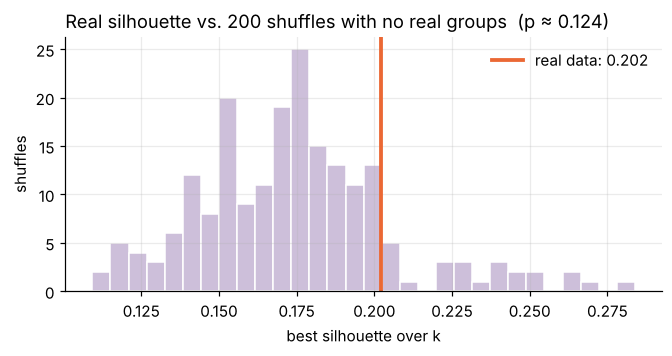

Doesn't clearly beat the shuffles: treat the groups as tendencies, not types (more games will help).


In [9]:
def best_silhouette(M):
    out = []
    for k in ks:
        lab = KMeans(k, n_init=10, random_state=SEED).fit_predict(M)
        out.append(silhouette_score(M, lab))
    return max(out)

actual = best_silhouette(X.values)
null = np.array([best_silhouette(np.column_stack([rng.permutation(X.values[:, j]) for j in range(X.shape[1])]))
                 for _ in range(N_PERMUTATIONS)])
p_value = (np.sum(null >= actual) + 1) / (len(null) + 1)

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(null, bins=30, color="#cdbfda", edgecolor="white")
ax.axvline(actual, color="#eb6834", lw=2.5, label=f"real data: {actual:.3f}")
ax.set_xlabel("best silhouette over k"); ax.set_ylabel("shuffles"); ax.legend(frameon=False)
ax.set_title(f"Real silhouette vs. {N_PERMUTATIONS} shuffles with no real groups  (p ≈ {p_value:.3f})", loc="left")
plt.show()
print("Beats the shuffles: there's structure beyond chance." if p_value < 0.05 else
      "Doesn't clearly beat the shuffles: treat the groups as tendencies, not types (more games will help).")

## 5. Are the groups stable?

Resample the **games** with replacement (as if a different set of evenings had been recorded), rebuild everything and
re-cluster. The adjusted Rand index (ARI) compares each re-run with the original grouping on the players in both
(1 = identical, 0 = no better than chance). Per player: how often they land with the same group-mates.

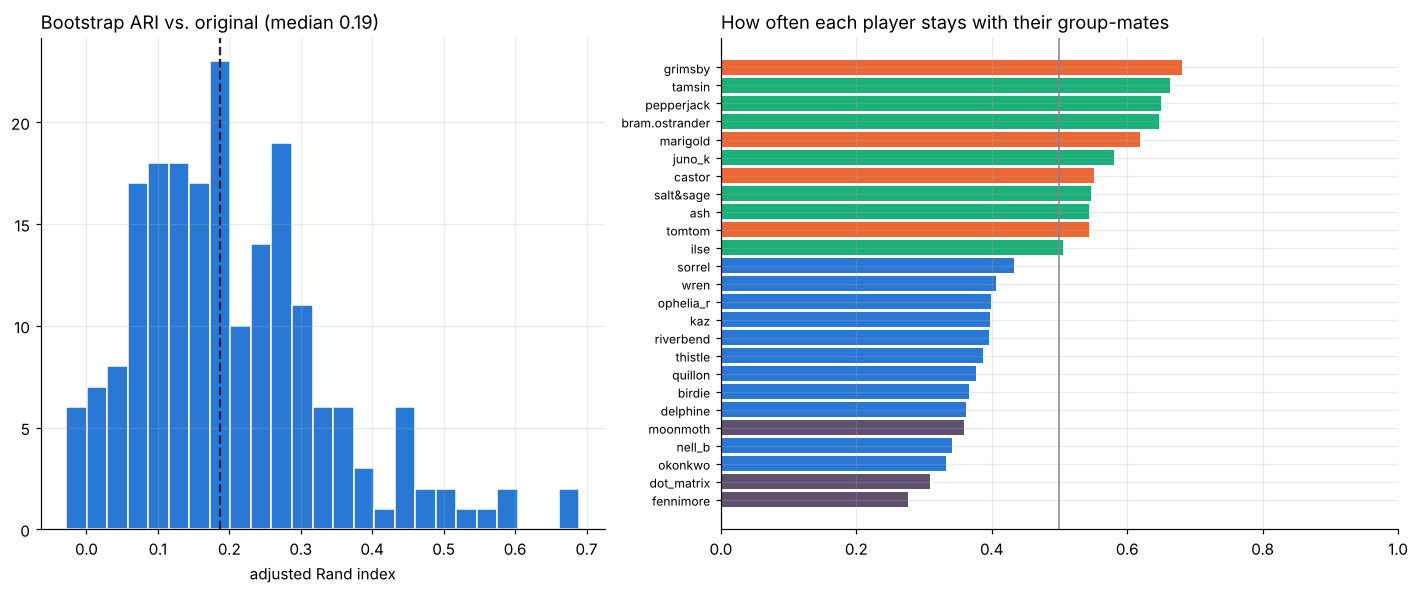

Rough guide: median ARI > 0.75 stable, 0.5–0.75 moderately stable, < 0.5 the grouping changes a lot with the games recorded.


In [10]:
ref = KMeans(best_k, n_init=30, random_state=SEED).fit(X)
ref_labels = pd.Series(ref.labels_, index=X.index)
by_game = {g: df for g, df in seats.groupby("game")}
game_ids = list(by_game)

aris, together = [], pd.DataFrame(0.0, index=X.index, columns=X.index)
seen_pairs = pd.DataFrame(0.0, index=X.index, columns=X.index)
for b in range(N_BOOTSTRAPS):
    pick = rng.choice(game_ids, size=len(game_ids), replace=True)
    boot = pd.concat([by_game[g].assign(game=f"{g}#{i}") for i, g in enumerate(pick)], ignore_index=True)
    Xb, _ = feature_matrix(player_table(boot, SIDE), SIDE, min_games)
    Xb = Xb.reindex(columns=X.columns).dropna(axis=1, how="all").fillna(0)
    common = Xb.index.intersection(X.index)
    if len(common) < best_k * 2:
        continue
    lab = pd.Series(KMeans(best_k, n_init=10, random_state=SEED).fit_predict(Xb), index=Xb.index)[common]
    aris.append(adjusted_rand_score(ref_labels[common], lab))
    same = (lab.values[:, None] == lab.values[None, :]).astype(float)
    together.loc[common, common] += same
    seen_pairs.loc[common, common] += 1
aris = np.array(aris)

# Per player: of the bootstraps where they and a reference group-mate both appeared, how often were they together?
co = together / seen_pairs.replace(0, np.nan)
stability = pd.Series({n: co.loc[n, ref_labels.index[(ref_labels == ref_labels[n]) & (ref_labels.index != n)]].mean() for n in X.index})

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, max(3, 0.22 * len(X))), gridspec_kw={"width_ratios": [1, 1.2]})
a1.hist(aris, bins=25, color="#2a78d6", edgecolor="white"); a1.axvline(np.median(aris), color="#2b1d3f", ls="--")
a1.set_title(f"Bootstrap ARI vs. original (median {np.median(aris):.2f})", loc="left"); a1.set_xlabel("adjusted Rand index")
st = stability.sort_values()
a2.barh(st.index, st.values, color=[GROUP_COLORS[ref_labels[n]] for n in st.index])
a2.set_xlim(0, 1); a2.axvline(0.5, color="#8b7f8e", lw=1); a2.set_title("How often each player stays with their group-mates", loc="left")
a2.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()
print("Rough guide: median ARI > 0.75 stable, 0.5–0.75 moderately stable, < 0.5 the grouping changes a lot with the games recorded.")

## 6. The groups

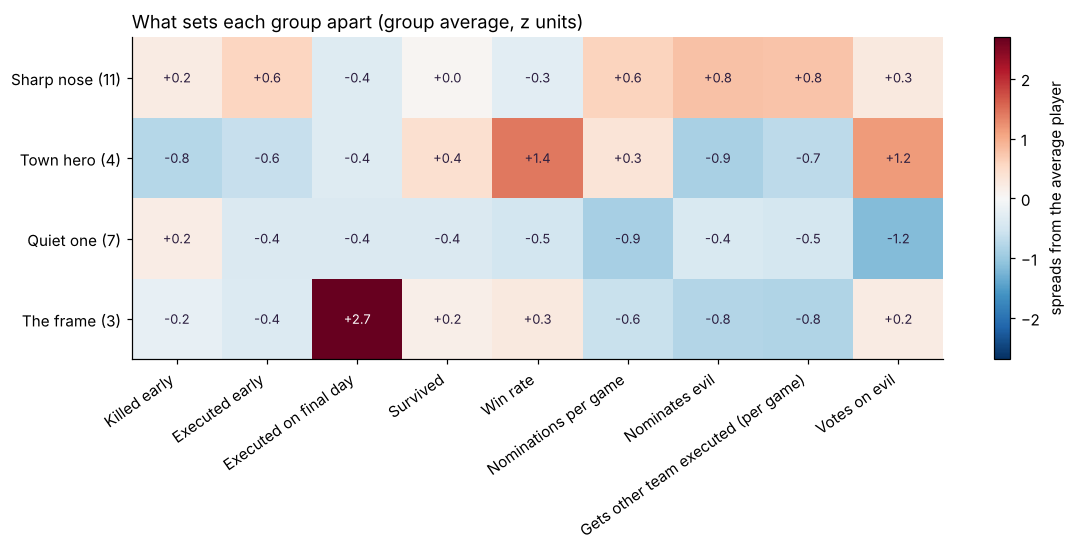

Sharp nose: wren, riverbend, okonkwo, thistle, quillon, sorrel, birdie, delphine, nell_b, kaz, ophelia_r
Town hero: grimsby, castor, marigold, tomtom
Quiet one: pepperjack, ash, juno_k, salt&sage, bram.ostrander, tamsin, ilse
The frame: moonmoth, dot_matrix, fennimore


In [11]:
centres = pd.DataFrame(ref.cluster_centers_, columns=X.columns)
names = name_groups(centres, SIDE)
centres.index = [f"{n} ({(ref_labels == i).sum()})" for i, n in enumerate(names)]

fig, ax = plt.subplots(figsize=(1.1 * len(feats) + 2, 0.6 * best_k + 1.4))
lim = max(1.5, np.abs(centres.values).max())
im = ax.imshow(centres, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(feats)), [FEATURES[f]["label"] for f in feats], rotation=35, ha="right"); ax.set_yticks(range(best_k), centres.index); ax.grid(False)
for i in range(best_k):
    for j in range(len(feats)):
        ax.text(j, i, f"{centres.iloc[i, j]:+.1f}", ha="center", va="center", fontsize=8.5, color="white" if abs(centres.iloc[i, j]) > lim * 0.6 else "#2b1d3f")
plt.colorbar(im, label="spreads from the average player"); ax.set_title("What sets each group apart (group average, z units)", loc="left")
plt.show()

for i, n in enumerate(names):
    print(f"{n}: {', '.join(ref_labels.index[ref_labels == i])}")

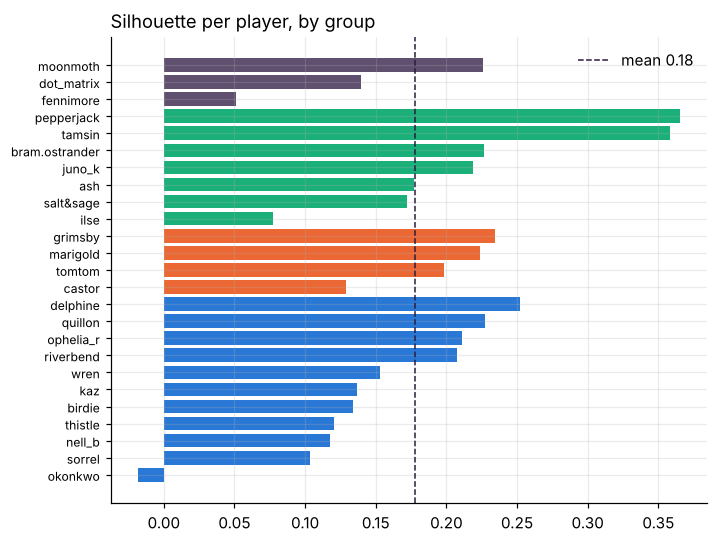

In [12]:
# Per-player silhouette: bars near 0 or below sit between groups (or in the wrong one).
sil = pd.Series(silhouette_samples(X, ref.labels_), index=X.index)
fig, ax = plt.subplots(figsize=(7, max(3, 0.22 * len(X))))
order = sorted(X.index, key=lambda n: (ref_labels[n], sil[n]))
ax.barh(order, sil[order], color=[GROUP_COLORS[ref_labels[n]] for n in order])
ax.axvline(sil.mean(), color="#2b1d3f", ls="--", lw=1, label=f"mean {sil.mean():.2f}")
ax.tick_params(axis="y", labelsize=8); ax.legend(frameon=False)
ax.set_title("Silhouette per player, by group", loc="left"); plt.show()

## 7. The map

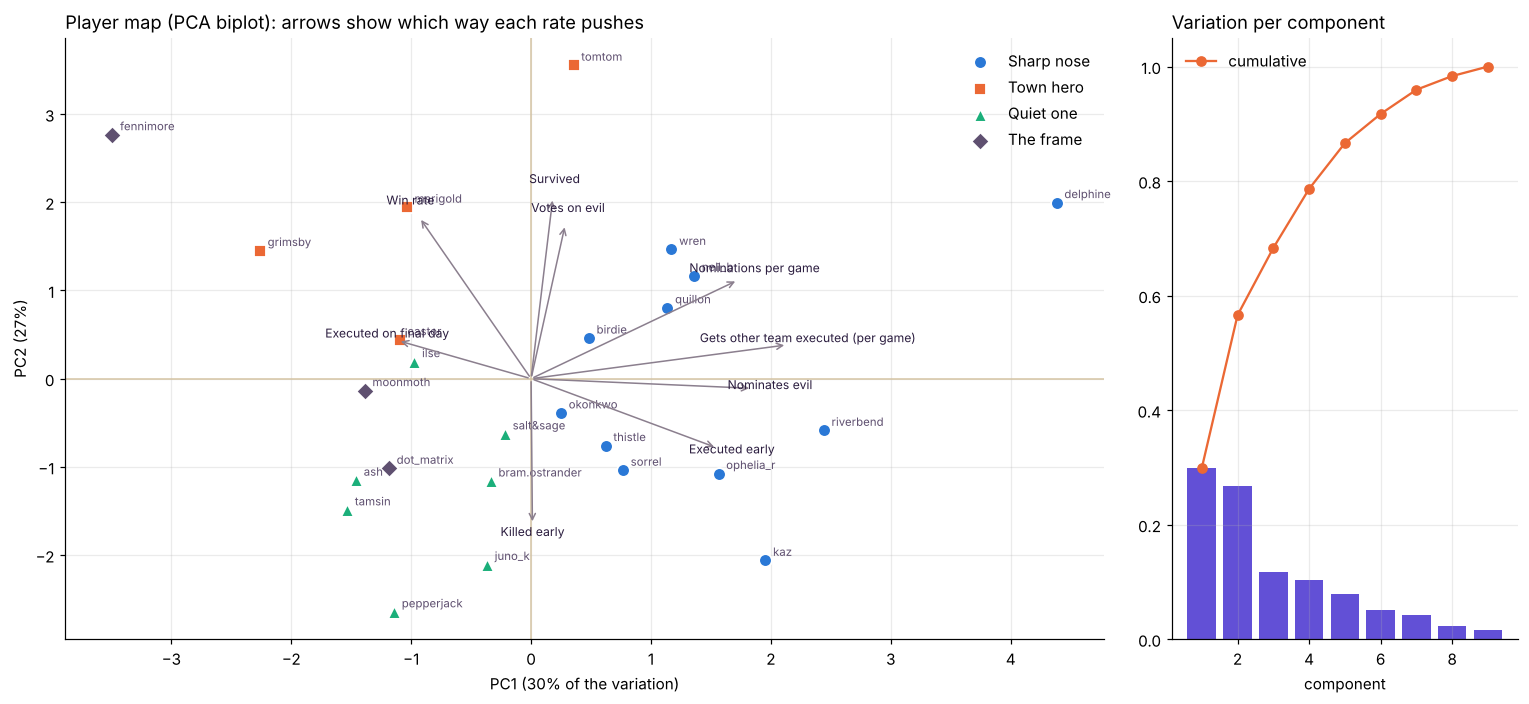

The 2-D map keeps 57% of the variation, so distances on it are approximate.


In [13]:
pca = PCA(n_components=min(len(feats), len(X))).fit(X)
xy = pca.transform(X)[:, :2]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [3, 1]})
markers = ["o", "s", "^", "D", "v", "P", "X", "*"]
for i, n in enumerate(names):
    m = ref_labels.values == i
    a1.scatter(xy[m, 0], xy[m, 1], s=70, marker=markers[i], color=GROUP_COLORS[i], edgecolor="white", linewidth=1.2, label=n, zorder=3)
for (x, y), n in zip(xy, X.index):
    a1.annotate(n, (x, y), fontsize=7.5, xytext=(5, 3), textcoords="offset points", color="#5f5070")
# Loadings: which way each feature pushes a player on the map.
scale = np.abs(xy).max() * 0.9
for j, f in enumerate(feats):
    lx, ly = pca.components_[0, j] * scale, pca.components_[1, j] * scale
    a1.annotate("", (lx, ly), (0, 0), arrowprops=dict(arrowstyle="->", color="#8b7f8e", lw=1))
    a1.text(lx * 1.08, ly * 1.08, FEATURES[f]["label"], fontsize=8, color="#2b1d3f", ha="center")
a1.axhline(0, color="#d5c4a4", lw=1); a1.axvline(0, color="#d5c4a4", lw=1)
ev = pca.explained_variance_ratio_
a1.set_xlabel(f"PC1 ({ev[0]:.0%} of the variation)"); a1.set_ylabel(f"PC2 ({ev[1]:.0%})")
a1.legend(frameon=False, loc="best"); a1.set_title("Player map (PCA biplot): arrows show which way each rate pushes", loc="left")
a2.bar(range(1, len(ev) + 1), ev, color="#6250d6"); a2.plot(range(1, len(ev) + 1), np.cumsum(ev), marker="o", color="#eb6834", label="cumulative")
a2.set_title("Variation per component", loc="left"); a2.set_xlabel("component"); a2.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"The 2-D map keeps {ev[:2].sum():.0%} of the variation, so distances on it are approximate.")

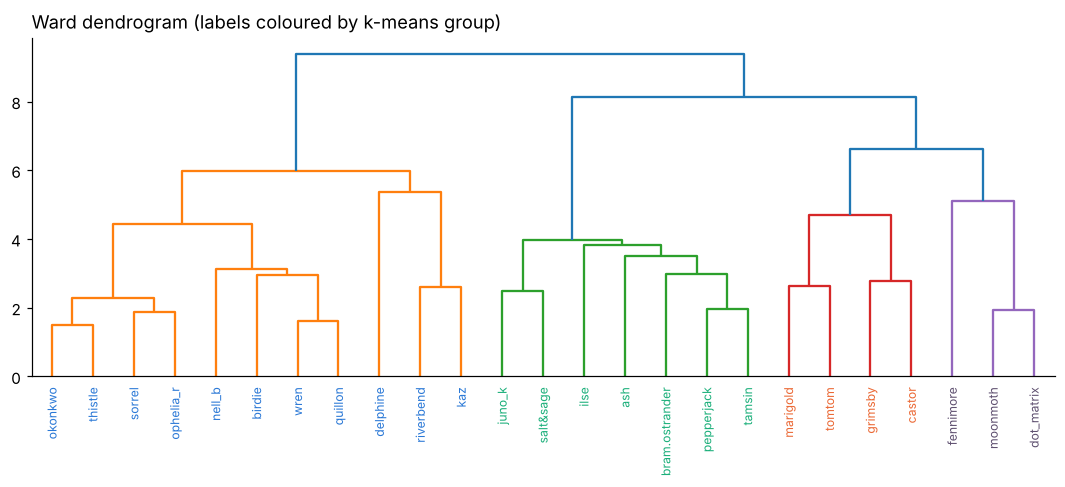

In [14]:
# A second opinion: Ward hierarchical clustering. If its top branches match the k-means groups, good sign.
Z = linkage(X.values, method="ward")
fig, ax = plt.subplots(figsize=(12, 4))
dendrogram(Z, labels=list(X.index), leaf_rotation=90, leaf_font_size=8, color_threshold=Z[-(best_k - 1), 2], ax=ax)
for t in ax.get_xticklabels():
    t.set_color(GROUP_COLORS[ref_labels[t.get_text()]])
ax.grid(False); ax.set_title("Ward dendrogram (labels coloured by k-means group)", loc="left"); plt.show()

## 8. Hound dogs / framers

In [15]:
tr = P[P["tracked"] > 0].copy()
hound = pd.DataFrame({
    "games": tr["tracked"],
    "noms_per_game": tr["noms"] / tr["tracked"],
    "noms_on_evil": tr["nomsOnEvil"] / tr["noms"].replace(0, np.nan),
    "other_team_executed": tr["enemyExecs"],
    "per_game": tr["enemyExecs"] / tr["tracked"],
    "per_game_shrunk": tr["s_enemyExecs"],
    "votes_on_evil": tr["votesOnEvil"] / tr["votes"].replace(0, np.nan),
}).sort_values("per_game_shrunk", ascending=False)
if SIDE != "good":
    hound = hound.drop(columns=["noms_on_evil", "votes_on_evil"])
display(hound.round(2))

,games,noms_per_game,noms_on_evil,other_team_executed,per_game,per_game_shrunk,votes_on_evil
delphine,8,1.25,0.70,4,0.50,0.35,0.50
wren,24,0.79,0.58,5,0.21,0.19,0.40
sorrel,9,0.67,0.50,2,0.22,0.18,0.42
riverbend,16,1.12,0.44,3,0.19,0.17,0.36
quillon,10,0.80,0.50,2,0.20,0.17,0.44
ophelia_r,5,0.80,0.75,1,0.20,0.15,0.33
kaz,5,1.00,0.40,1,0.20,0.15,0.46
salt&sage,13,0.54,0.29,2,0.15,0.14,0.36
nell_b,8,0.75,0.67,1,0.12,0.11,0.53
tomtom,8,1.38,0.36,1,0.12,0.11,0.58
